# Titanic Survival Prediction Using Logistic Regression

## 1. Problem Statement

The Titanic disaster was a major maritime disaster in which many passengers lost their lives while others survived. The objective of this project is to explore passenger information and support the development of a machine-learning model that predicts whether a passenger survived.

## 2. Motivation

This project demonstrates how machine learning can identify patterns in historical data and use passenger attributes to make predictions. We explore variables such as age, gender, passenger class and fare to understand how they are associated with survival.

## 3. Dataset Description

The dataset used in this project is the Titanic passenger dataset (`Titanic-Dataset.csv`). It contains passenger-level information. The target variable is `Survived`: **0** means the passenger did not survive and **1** means the passenger survived.

The notebook expects the CSV file to be named **`titanic.csv`** and placed in the same folder as this notebook. This relative path makes the project easier for teammates and evaluators to run after cloning the repository.

## 4. Import Libraries

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("titanic.csv")

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Keep plots readable and consistent


print("All libraries imported successfully!")

All libraries imported successfully!


## 5. Load the Dataset

Keep `titanic.csv` in the same directory as this notebook. Avoid using a personal computer's absolute file path, because it will not work on another team member's computer.

In [3]:
df = pd.read_csv("titanic.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


## 6. Initial Dataset Exploration

We inspect sample records, the dataset dimensions, column data types and missing values before performing exploratory data analysis.

In [4]:
# First five records
display(df.head())

# Dataset dimensions (rows, columns)
print("Dataset shape:", df.shape)

# Column names, non-null counts and data types
print("\nDataset information:")
df.info()

# Missing values in each column
print("\nMissing values:")
display(df.isnull().sum().to_frame(name="Missing Values"))

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Dataset shape: (891, 12)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

Missing values:


,Missing Values
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


## 7. Exploratory Data Analysis (EDA)

EDA uses tables and visualizations to understand the target variable and explore relationships between passenger attributes and survival. The plots in this section are descriptive; they do not by themselves prove causation.

### 7.1 Overall Survival Distribution

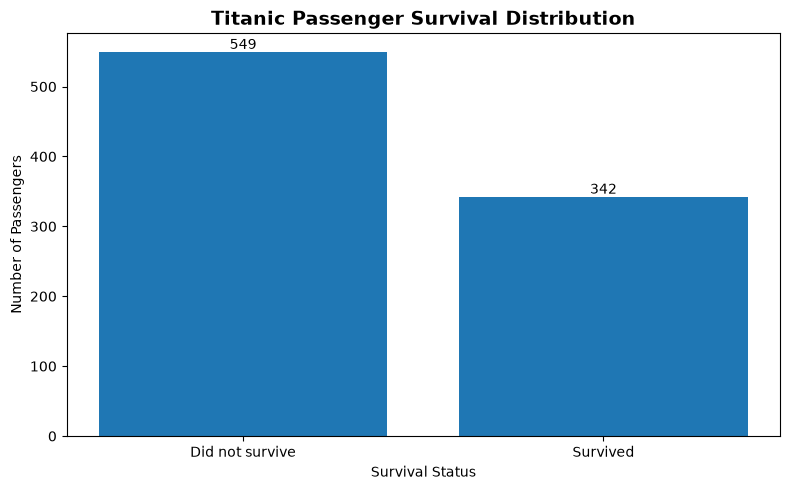

Survival counts:
Survived
0    549
1    342
Name: count, dtype: int64

Survival percentages:
Survived
0    61.6
1    38.4
Name: proportion, dtype: float64


In [5]:
counts = df["Survived"].value_counts().reindex([0, 1])
plt.figure(figsize=(8, 5))
bars = plt.bar(["Did not survive", "Survived"], counts.values)
plt.title("Titanic Passenger Survival Distribution", fontsize=14, fontweight="bold")
plt.xlabel("Survival Status")
plt.ylabel("Number of Passengers")
plt.bar_label(bars)
plt.tight_layout()
plt.show()

print("Survival counts:")
print(counts)
print("\nSurvival percentages:")
print((df["Survived"].value_counts(normalize=True).reindex([0, 1]) * 100).round(1))

**Interpretation:** In this dataset, 549 passengers did not survive and 342 survived. Therefore, the number of non-survivors is greater than the number of survivors. The target classes are not perfectly balanced.

### 7.2 Survival Rate by Gender

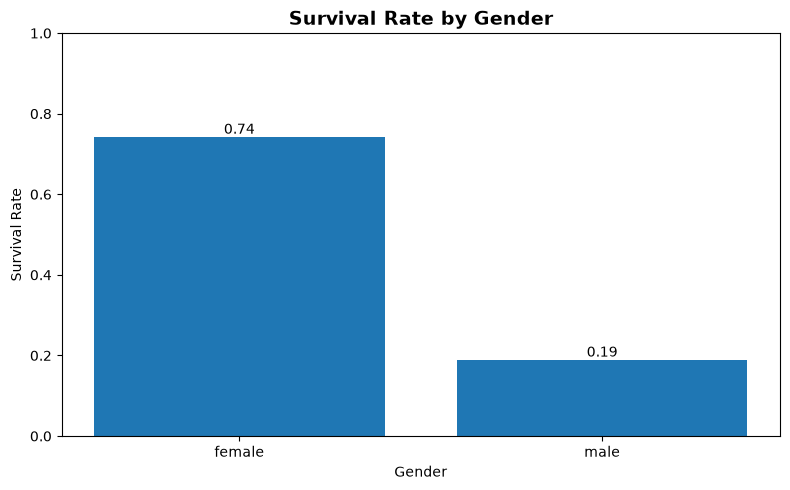

Sex
female    74.2%
male      18.9%
Name: Survived, dtype: str


In [6]:
gender_rates = df.groupby("Sex")["Survived"].mean().reindex(["female", "male"])
plt.figure(figsize=(8, 5))
bars = plt.bar(gender_rates.index, gender_rates.values)
plt.title("Survival Rate by Gender", fontsize=14, fontweight="bold")
plt.xlabel("Gender")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)
plt.bar_label(bars, fmt="%.2f")
plt.tight_layout()
plt.show()

print((gender_rates * 100).round(1).astype(str) + "%")

**Interpretation:** The observed survival rate was approximately 74% for female passengers and 19% for male passengers. This is a substantial difference in the dataset and suggests that gender is strongly associated with survival.

### 7.3 Survival Rate by Passenger Class

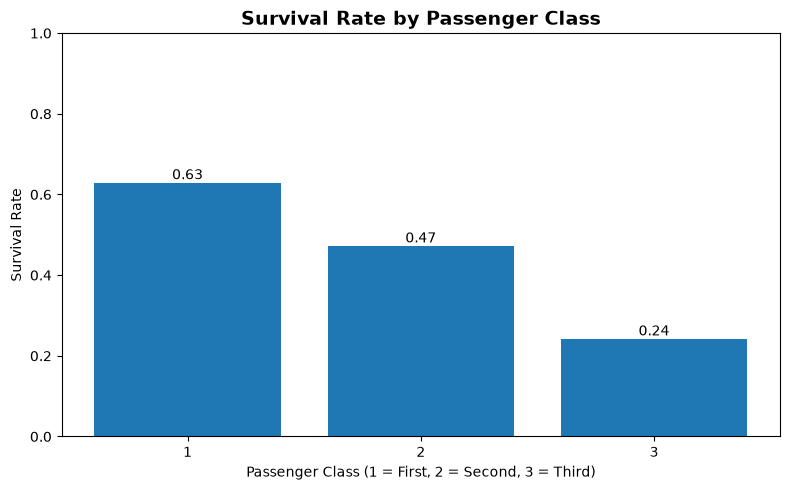

Pclass
1    63.0%
2    47.3%
3    24.2%
Name: Survived, dtype: str


In [7]:
class_rates = df.groupby("Pclass")["Survived"].mean().reindex([1, 2, 3])
plt.figure(figsize=(8, 5))
bars = plt.bar(class_rates.index.astype(str), class_rates.values)
plt.title("Survival Rate by Passenger Class", fontsize=14, fontweight="bold")
plt.xlabel("Passenger Class (1 = First, 2 = Second, 3 = Third)")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)
plt.bar_label(bars, fmt="%.2f")
plt.tight_layout()
plt.show()

print((class_rates * 100).round(1).astype(str) + "%")

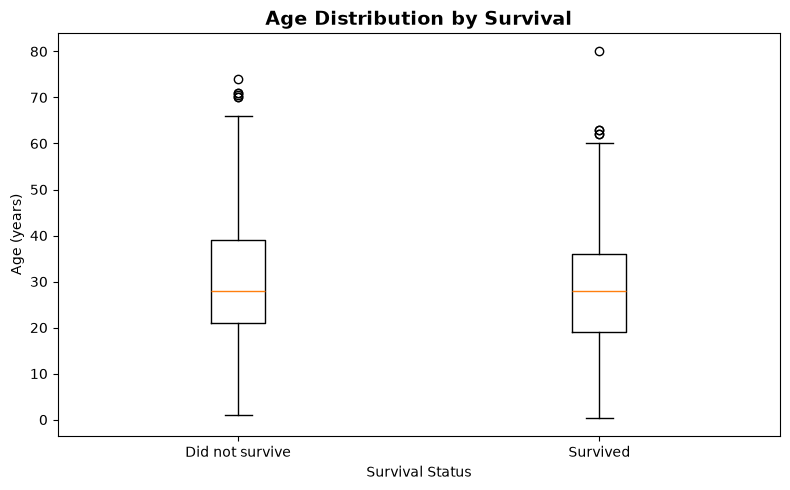

In [16]:

age_groups = [df.loc[df["Survived"] == value, "Age"].dropna() for value in [0, 1]]

plt.figure(figsize=(8, 5))
plt.boxplot(age_groups, tick_labels=["Did not survive", "Survived"])
plt.title("Age Distribution by Survival", fontsize=14, fontweight="bold")
plt.xlabel("Survival Status")
plt.ylabel("Age (years)")
plt.tight_layout()
plt.show()

**Interpretation:** First-class passengers had the highest observed survival rate (about 63%), followed by second-class passengers (about 47%) and third-class passengers (about 24%). Passenger class is therefore associated with survival in this dataset.

### 7.4 Age Distribution by Survival

**Interpretation:** The boxplot compares the age distributions of survivors and non-survivors. It allows us to compare their medians, spread and possible outliers. The distributions overlap, so age alone does not clearly separate the two groups. Age may still provide useful information when combined with other features. Missing age values are omitted automatically from this plot.

### 7.5 Correlation Heatmap

The heatmap below uses the numerical columns shown. `Sex` and `Embarked` are categorical and are therefore not included in this numerical correlation matrix.

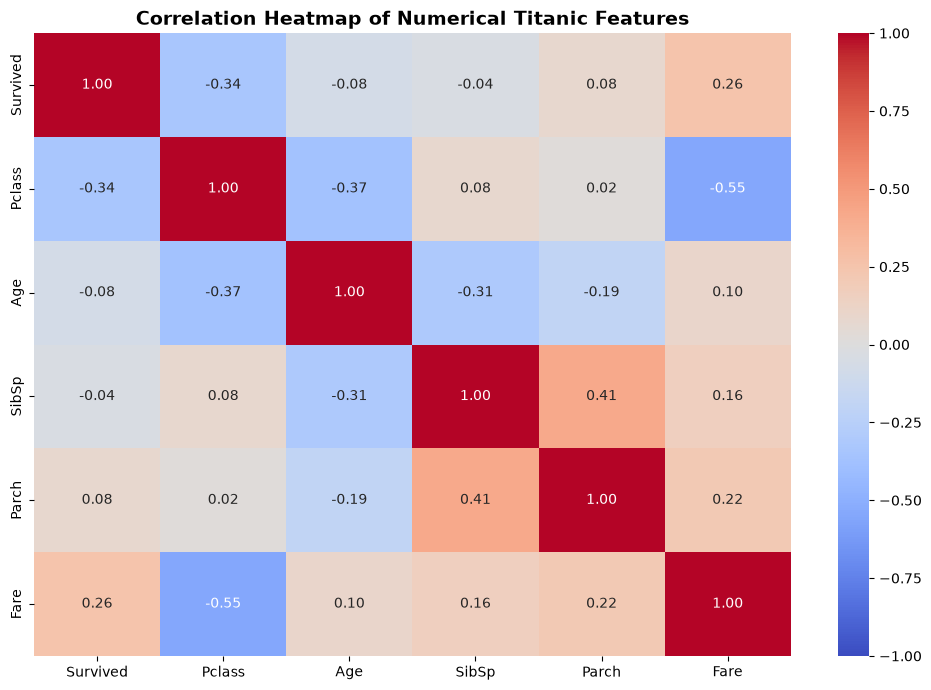

In [14]:
numeric_columns = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]
correlation = df[numeric_columns].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap of Numerical Titanic Features", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretation of Correlation Heatmap**

- **Pclass:** Has a negative correlation with `Survived`. Since a smaller Pclass number represents a higher passenger class, this indicates that higher-class passengers tended to have higher survival rates.
- **Fare:** Has a positive correlation with survival; passengers who paid higher fares tended, on average, to have higher survival rates.
- **Age:** Has a weak linear correlation with survival in this dataset.
- **SibSp and Parch:** Have relatively weak individual linear correlations with survival.

These correlations are useful for initial exploration, but they do not establish causation or capture every possible relationship. Categorical variables such as `Sex` can still be important even though they are not shown in this numerical heatmap.

## 8. EDA Conclusion

The exploratory analysis revealed several patterns in the Titanic dataset:

1. More passengers did not survive than survived.
2. Female passengers had a substantially higher survival rate than male passengers.
3. First-class passengers had higher survival rates than second- and third-class passengers.
4. The age distributions of survivors and non-survivors overlap, so age is more informative when considered alongside other features.
5. The correlation heatmap shows that passenger class and fare have noticeable correlations with survival, while the individual linear correlations of age, `SibSp` and `Parch` are weaker.

EDA helps us understand the data, identify missing values and recognize potentially useful features before preprocessing and training the Logistic Regression model. These are associations in this dataset, not proof that any one feature caused survival.

## 9. Handoff to the Preprocessing Section

The following observations may guide the next project section:

- `Age` contains missing values and can be imputed using the training data's median.
- `Embarked` contains a small number of missing values and can be imputed using the training data's mode.
- `Cabin` has many missing values; the team can consider dropping it and document that decision.
- `Sex` and `Embarked` are categorical variables and need encoding before Logistic Regression.
- `PassengerId`, `Name` and `Ticket` are identifiers or high-cardinality text fields that may be excluded in the team's baseline model.

**Important:** Fit preprocessing steps (such as imputation and scaling) using the training split only, then apply the fitted transformations to the test split to avoid data leakage.